In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_excel('/content/Telco_Customer_Churn_Dataset - Stock.xlsx')

# Task 1


*   Handle missing values in the dataset.

As in excel we already have seen some values from total charges missing which we solved

*   Convert categorical variables into
numerical representations using
techniques like one-hot encoding.

So we will be using label Encoding for this Task



In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [5]:
# the column customer_id serves no purpose hence we are dropping that

data.drop(columns='customerID',inplace=True)

In [6]:
# and we know its a churn lets simply see if we can build a prediction model lets start with Logistic regression
# and before we start we get first to preprocess it

from sklearn.preprocessing import LabelEncoder, StandardScaler

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [8]:
# as many values are categorical  we would change these into numerical hence labelEncoding
# also a better way is to assign value individually but that would take a lot and time and we just
# need to make patterns so ML algo can understand

columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

In [9]:
# a simply used a loop to make these transformation rather than taking it one by one.
# so we have a complete label encoder

le = LabelEncoder()
for i in columns:
  data[''+i+''] = le.fit_transform(data[''+i+''])

data

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,No
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,No
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,Yes
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,No
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,2,0,2,0,2,2,2,2,1,1,3,84.80,1990.50,No
7039,0,0,1,1,72,1,2,1,0,2,2,0,2,2,1,1,1,103.20,7362.90,No
7040,0,0,1,1,11,0,1,0,2,0,0,0,0,0,0,1,2,29.60,346.45,No
7041,1,1,1,0,4,1,2,1,0,0,0,0,0,0,0,1,3,74.40,306.60,Yes


# Task 2

Overall churn rate: 26.5%  (1869 of 7043)


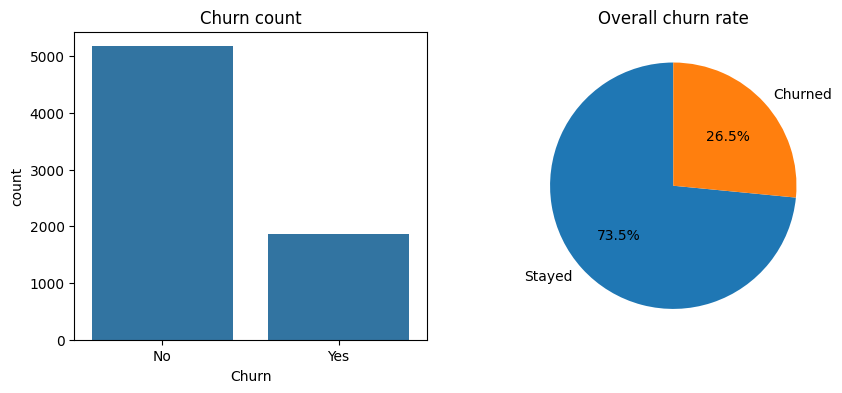

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
# lets get the overall churn rate first

counts = data.Churn.value_counts()
rate = (data.Churn=='Yes').mean() * 100
print(f"Overall churn rate: {rate:.1f}%  ({counts['Yes']} of {len(data.Churn=='Yes')})")


fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=data, x="Churn", order=["No", "Yes"], ax=ax[0])
ax[0].set_title("Churn count")
ax[1].pie(counts[["No", "Yes"]], labels=["Stayed", "Churned"],
          autopct="%1.1f%%", startangle=90)
ax[1].set_title("Overall churn rate")

plt.show()

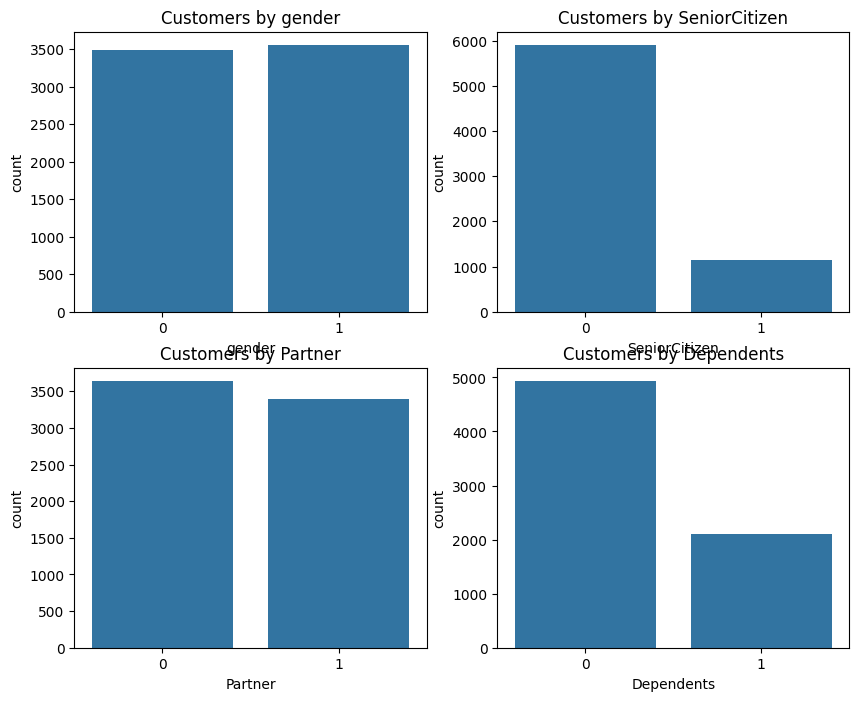

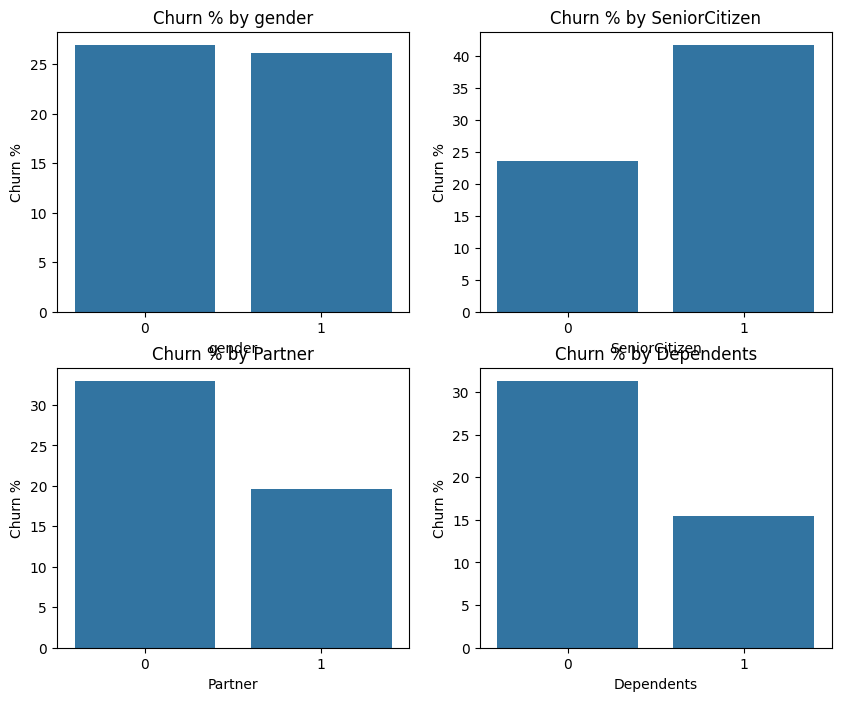

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
# lets get customer sgmention
demo = ["gender", "SeniorCitizen", "Partner", "Dependents"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for a, col in zip(axes.ravel(), demo):
    sns.countplot(data=data, x=col, ax=a)
    a.set_title(f"Customers by {col}")
plt.show()



# churn rate within each demographic group
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for a, col in zip(axes.ravel(), demo):
    r = data.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean()).mul(100)
    sns.barplot(x=r.index, y=r.values, ax=a)
    a.set_title(f"Churn % by {col}"); a.set_ylabel("Churn %")
plt.show()

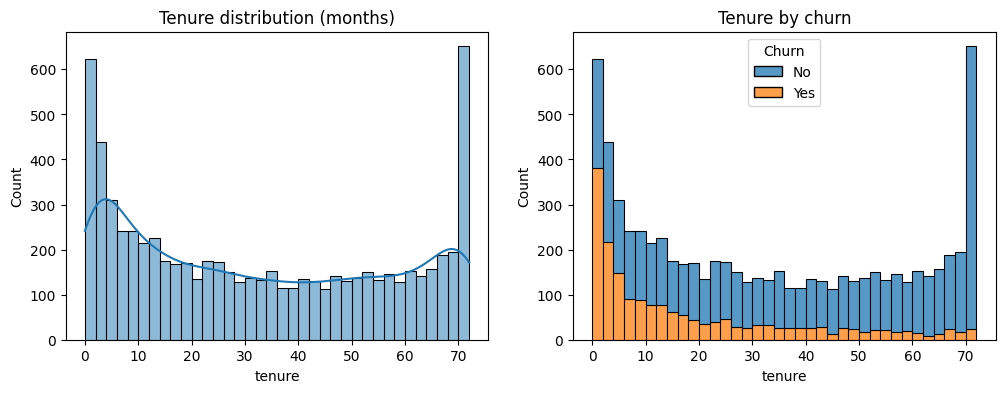

In [12]:
# Now plotting tenure vs churn
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data.tenure, bins=36, kde=True, ax=ax[0])
ax[0].set_title("Tenure distribution (months)")
sns.histplot(data=data, x="tenure", hue="Churn", bins=36, multiple="stack", ax=ax[1])
ax[1].set_title("Tenure by churn")
plt.show()


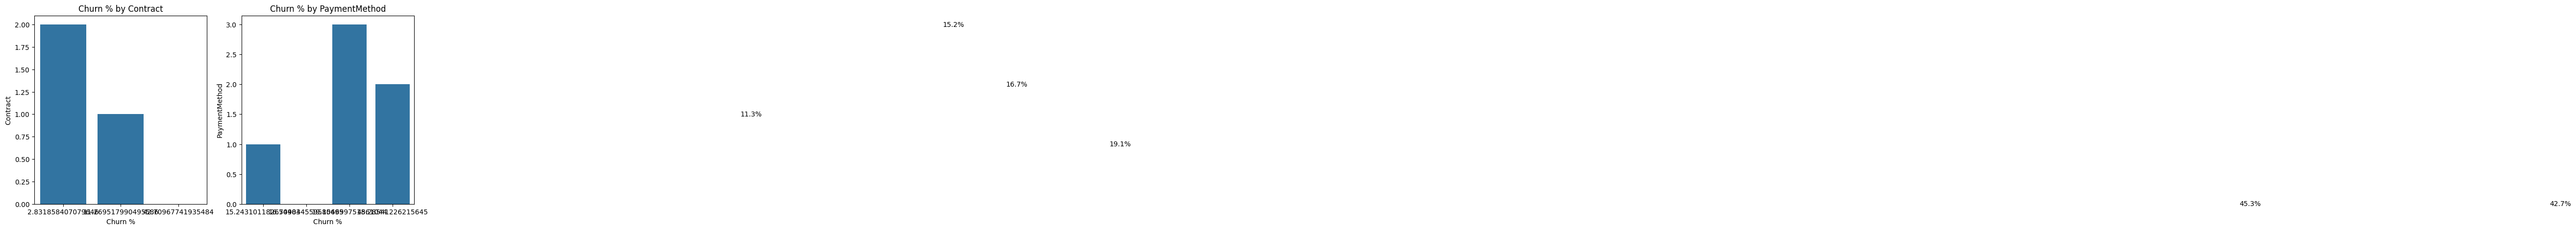

In [25]:
# contract & payment method
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for a, col in zip(axes, ["Contract", "PaymentMethod"]):
    r = data.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean()).mul(100).sort_values(ascending=False)
    sns.barplot(x=r.values, y=r.index, ax=a)
    a.set_title(f"Churn % by {col}"); a.set_xlabel("Churn %")
    for i, v in enumerate(r.values):
        a.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.show()

# Task 3

In [14]:
data["tenure_seg"] = pd.cut(data.tenure, [-1,12,24,48,72], labels=["0-12", "13-24", "25-48", "49-72"])
data["charge_seg"] = pd.qcut(data.MonthlyCharges, 3, labels=["Low","Medium","High"])

# Task 4

In [15]:
# And before we standardtize it we will create labels and data

X = data.drop(columns='Churn')
y = data['Churn']

In [16]:
# and we forgot to convert column churn
y = le.fit_transform(y)

In [17]:
y = pd.DataFrame(y)
y

,0
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [18]:
# Now applying train test split

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [19]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((5634, 21), (1409, 21), (5634, 1), (1409, 1))

In [22]:
# Scale the data using StandardScaler
from sklearn.preprocessing import StandardScaler
import pandas as pd

# One-hot encode the categorical columns that are still strings
# 'tenure_seg' and 'charge_seg' were created with string labels and are of object dtype
X_train_encoded = pd.get_dummies(X_train, columns=['tenure_seg', 'charge_seg'], drop_first=False)
X_test_encoded = pd.get_dummies(X_test, columns=['tenure_seg', 'charge_seg'], drop_first=False)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

#Logistic regression

In [23]:
from sklearn.linear_model import LogisticRegression
lr  = LogisticRegression(max_iter=1000) # Increased max_iter to help convergence
# Convert y_train and y_test to 1D arrays
lr.fit(X_train_scaled,y_train.values.ravel())
lr.predict(X_test_scaled)

array([1, 0, 0, ..., 0, 0, 1])

0.8112136266855926
Axes(0.125,0.11;0.62x0.77)
              precision    recall  f1-score   support

           0       0.85      0.90      0.88      1036
           1       0.67      0.56      0.61       373

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.81      1409



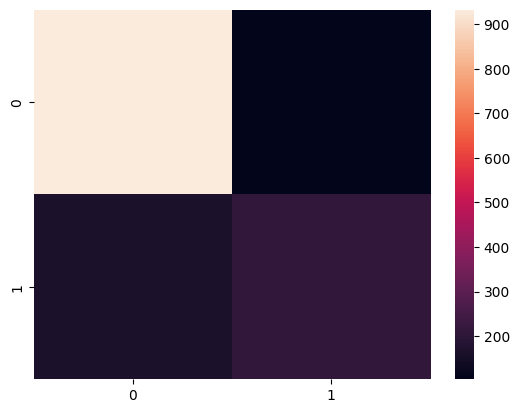

In [24]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = lr.predict(X_test_scaled)
print(accuracy_score(y_test,y_pred))
print(sns.heatmap(confusion_matrix(y_test,y_pred)))
print(classification_report(y_test,y_pred))

# Task 5

# Task 6